In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
data = pd.DataFrame({
    "hours": [1, 1.5, 2, 2.5, 3, 3.2, 3.5, 4, 4.5, 5,
              5.5, 6, 6.5, 7, 7.5, 8, 8.5, 9, 9.5, 10],
    "passed": [0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
               0, 1, 1, 1, 1, 1, 1, 1, 1, 1]
})

print(data)
# 3.5 hours passed, 6 hours failed.

X = data[["hours"]]   # the input (feature)
y = data["passed"]    # the answer (label)

model = LogisticRegression()
model.fit(X, y) # study the data or learning step


print("Intercept:", model.intercept_) # b
print("Coefficient:", model.coef_) # w

#Normal programming: you write the rule yourself, for example “if hours > 5 then pass”.
#Machine learning: you give examples, and the computer works out the rule itself.

#y = wx + b
#z = intercept + coefficient × hours
#z = -4.5 + 0.9 × hours

#  Generate predicted probabilities
probs = model.predict_proba(X)            # two columns: [P(fail), P(pass)]
data["prob_pass"] = probs[:, 1]           # keep only the pass case


# Turn probabilities into prediction
data["predicted"] = (data["prob_pass"] >= 0.5).astype(int)   # threshold 0.5
# Predicted Class = 1 if the probability is greater than or equal to 0.5
# Predicted Class = 0 if the probability is less than 0.5


# Compare predicted and actual labels
data["correct"] = data["passed"] == data["predicted"]
# to find out how good the model is.
# if passed and predicted matched, give true else fail.

print("\nACTUAL vs PREDICTED")
print(data.round(2)) #0.776543 = 0.78
print("\nCorrect predictions:", data["correct"].sum(), "out of", len(data))
print("Accuracy:", data["correct"].mean())
# data["correct"].sum(), no of correct predictions


#Examine the incorrect predictions
mistakes = data[data["correct"] == False]
print("\nINCORRECT PREDICTIONS")
print(mistakes.round(2))

# Check the sigmoid by hand
b0 = model.intercept_[0]
b1 = model.coef_[0][0]

hours = 6
z = b0 + b1 * hours
manual_prob = 1 / (1 + np.exp(-z))

six_hours = pd.DataFrame({"hours": [hours]})

print("\nMANUAL CHECK FOR 6 HOURS")
print("z =", round(z, 3))
print("My manual probability:", round(manual_prob, 3))
print("Model's probability:  ", round(model.predict_proba(six_hours)[0][1], 3))






















#  Predict a new student
new_student = pd.DataFrame({"hours": [6]})
print("\nNEW STUDENT (6 hours)")
print("Probability [fail, pass]:", model.predict_proba(new_student).round(3))




    hours  passed
0     1.0       0
1     1.5       0
2     2.0       0
3     2.5       0
4     3.0       0
5     3.2       0
6     3.5       1
7     4.0       0
8     4.5       0
9     5.0       1
10    5.5       0
11    6.0       1
12    6.5       1
13    7.0       1
14    7.5       1
15    8.0       1
16    8.5       1
17    9.0       1
18    9.5       1
19   10.0       1
Intercept: [-5.08071409]
Coefficient: [[1.05471759]]

ACTUAL vs PREDICTED
    hours  passed  prob_pass  predicted  correct
0     1.0       0       0.02          0     True
1     1.5       0       0.03          0     True
2     2.0       0       0.05          0     True
3     2.5       0       0.08          0     True
4     3.0       0       0.13          0     True
5     3.2       0       0.15          0     True
6     3.5       1       0.20          0    False
7     4.0       0       0.30          0     True
8     4.5       0       0.42          0     True
9     5.0       1       0.55          1     True
10    5.5

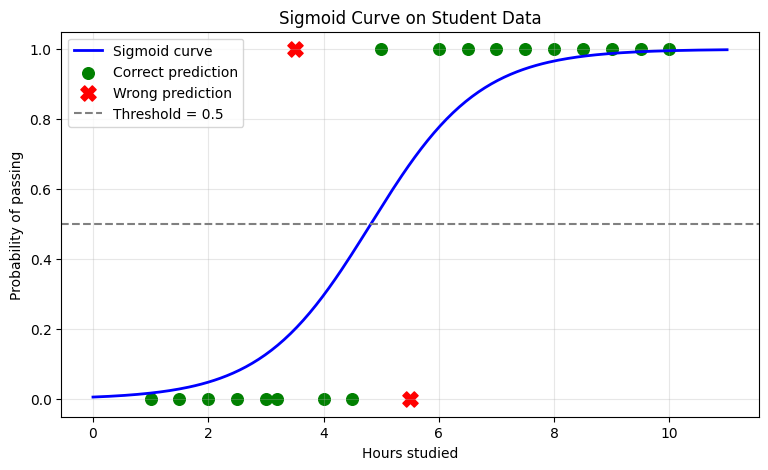

In [ ]:
import matplotlib.pyplot as plt

# Numbers the model learned
b0 = model.intercept_[0]
b1 = model.coef_[0][0]

# Draw the S-curve for hours from 0 to 11
hours_range = np.linspace(0, 11, 200)
z_range = b0 + b1 * hours_range
prob_range = 1 / (1 + np.exp(-z_range)) # sigmond function

# Split students into correct and wrong predictions
right = data[data["correct"] == True]
wrong = data[data["correct"] == False]

# Draw the graph
plt.figure(figsize=(9, 5))
plt.plot(hours_range, prob_range, color="blue", linewidth=2, label="Sigmoid curve")
plt.scatter(right["hours"], right["passed"], color="green", s=70, label="Correct prediction")
plt.scatter(wrong["hours"], wrong["passed"], color="red", s=120, marker="X", label="Wrong prediction")
plt.axhline(0.5, color="gray", linestyle="--", label="Threshold = 0.5")

plt.xlabel("Hours studied")
plt.ylabel("Probability of passing")
plt.title("Sigmoid Curve on Student Data")
plt.legend()
plt.grid(alpha=0.3)
plt.show()